In [ ]:
!pip -q install vmas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 218.0/218.0 kB 7.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 36.1 MB/s eta 0:00:00


In [ ]:
import vmas
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

env = vmas.make_env(
    scenario="navigation",
    num_envs=1,
    n_agents=2,
    device=DEVICE,
    continuous_actions=True,
    max_steps=100,
    seed=42,
)

obs = env.reset()

print("Device:", DEVICE)
print("Agents:", len(env.agents))

for i, agent_obs in enumerate(obs):
    print(f"Agent {i} observation:", agent_obs.shape)

Device: cuda
Agents: 2
Agent 0 observation: torch.Size([1, 18])
Agent 1 observation: torch.Size([1, 18])


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
actions = env.get_random_actions()

obs, rewards, dones, infos = env.step(actions)

for i, agent in enumerate(env.agents):
    print(f"Agent {i}")
    print("Position:", agent.state.pos)
    print("Velocity:", agent.state.vel)
    print("Reward:", rewards[i])

print("Done:", dones)

Agent 0
Position: tensor([[-0.2411, -0.5625]], device='cuda:0')
Velocity: tensor([[-0.0320, -0.0247]], device='cuda:0')
Reward: tensor([0.0047], device='cuda:0')
Agent 1
Position: tensor([[-0.4758,  0.4825]], device='cuda:0')
Velocity: tensor([[ 0.0830, -0.0410]], device='cuda:0')
Reward: tensor([0.0047], device='cuda:0')
Done: tensor([False], device='cuda:0')


In [ ]:
!apt-get update -qq
!apt-get install -y -qq libglu1-mesa libgl1 libgl1-mesa-dri xvfb
!pip -q install pyvirtualdisplay

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
(Reading database ... 127332 files and directories currently installed.)
Preparing to unpack .../0-libgl1-mesa-dri_25.2.8-0ubuntu0.24.04.4_amd64.deb ...
Unpacking libgl1-mesa-dri:amd64 (25.2.8-0ubuntu0.24.04.4) over (25.2.8-0ubuntu0.24.04.3) ...
Preparing to unpack .../1-libglx-mesa0_25.2.8-0ubuntu0.24.04.4_amd64.deb ...
Unpacking libglx-mesa0:amd64 (25.2.8-0ubuntu0.24.04.4) over (25.2.8-0ubuntu0.24.04.3) ...
Preparing to unpack .../2-libegl-mesa0_25.2.8-0ubuntu0.24.04.4_amd64.deb ...
Unpacking libegl-mesa0:amd64 (25.2.8-0ubuntu0.24.04.4) over (25.2.8-0ubuntu0.24.04.3) ...
Preparing to unpack .../3-libgbm1_25.2.8-0ubuntu0.24.04.4_amd64.deb ...
Unpacking libgbm1:amd64 (25.2.8-0ubuntu0.24.04.4) over (25.2.8-0ubuntu0.24.04.3) ...
Preparing to unpack .../4-mesa-libgallium_25.2.8-0ubuntu0.24.04.4_amd64.de

In [ ]:
import os

os.environ["LIBGL_ALWAYS_SOFTWARE"] = "1"

from pyvirtualdisplay import Display

virtual_display = Display(
    visible=False,
    size=(1400, 900),
    color_depth=24
)

virtual_display.start()

print("Virtual display:", os.environ.get("DISPLAY"))

Virtual display: :0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Frame shape: (700, 700, 3)


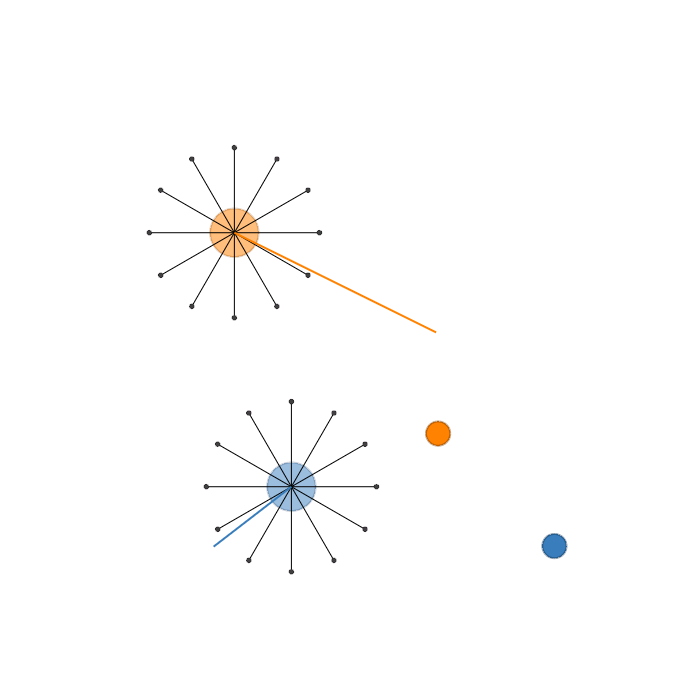

In [ ]:
from IPython.display import display
from PIL import Image

frame = env.render(mode="rgb_array")

print("Frame shape:", frame.shape)
display(Image.fromarray(frame))

In [ ]:
#Step 5：固定双机交叉场景
import vmas
import torch
import numpy as np

MAX_STEPS = 200

env = vmas.make_env(
    scenario="navigation",
    num_envs=1,
    n_agents=2,
    device=DEVICE,
    continuous_actions=True,
    max_steps=MAX_STEPS,
    seed=42,
)

env.reset()

import torch
import numpy as np

# 使用前面已经创建的 env
env.reset()

device = env.agents[0].state.pos.device

starts = [
    [-0.8, -0.8],
    [-0.8,  0.8]
]

goals = [
    [0.8,  0.8],
    [0.8, -0.8]
]

with torch.no_grad():
    for i, agent in enumerate(env.agents):
        start = torch.tensor(starts[i], device=device, dtype=torch.float32)
        goal = torch.tensor(goals[i], device=device, dtype=torch.float32)

        agent.set_pos(start, batch_index=0)
        agent.set_vel(torch.zeros(2, device=device), batch_index=0)
        agent.goal.set_pos(goal, batch_index=0)

        # 更新导航场景中的奖励整形基准
        agent.pos_shaping[0] = torch.linalg.vector_norm(
            agent.state.pos[0] - agent.goal.state.pos[0]
        ) * env.scenario.pos_shaping_factor

print("Fixed crossing scenario initialized.")


Fixed crossing scenario initialized.


In [ ]:
#Step 6：让 Agent 自动向目标移动
import time
import numpy as np
import torch

KP = 1.5
KD = 1.0
SAFE_DISTANCE = 0.30
GOAL_TOL = 0.12

trajectories = [[] for _ in env.agents]
separations = []
planning_times = []

joint_success = False
termination_reason = "max_steps"

for step in range(MAX_STEPS):

    # 1. 记录当前状态
    for i, agent in enumerate(env.agents):
        trajectories[i].append(
            agent.state.pos[0].detach().cpu().numpy().copy()
        )

    p0 = env.agents[0].state.pos[0]
    p1 = env.agents[1].state.pos[0]

    separation = torch.linalg.vector_norm(p0 - p1).item()
    separations.append(separation)

    # 2. 检查是否共同到达目标
    goal_distances = [
        torch.linalg.vector_norm(
            agent.state.pos[0] - agent.goal.state.pos[0]
        ).item()
        for agent in env.agents
    ]

    if all(d < GOAL_TOL for d in goal_distances):
        joint_success = True
        termination_reason = "joint_success"
        break

    # 3. PD 控制器计算动作
    start_time = time.perf_counter()
    actions = []

    for agent in env.agents:
        pos = agent.state.pos
        vel = agent.state.vel
        goal = agent.goal.state.pos

        action = KP * (goal - pos) - KD * vel

        limit = float(agent.u_range)
        action = torch.clamp(action, -limit, limit)

        actions.append(action)

    planning_times.append(time.perf_counter() - start_time)

    # 4. 执行动作并检查 VMAS 终止信号
    obs, rewards, dones, infos = env.step(actions)

    if bool(torch.all(dones)):
        termination_reason = "environment_done"
        break

# 5. 记录最终状态
for i, agent in enumerate(env.agents):
    trajectories[i].append(
        agent.state.pos[0].detach().cpu().numpy().copy()
    )

p0 = env.agents[0].state.pos[0]
p1 = env.agents[1].state.pos[0]

separations.append(
    torch.linalg.vector_norm(p0 - p1).item()
)

trajectories = [
    np.array(t) for t in trajectories
]
separations = np.array(separations)

# 6. 最终检查是否到达目标
joint_success = all(
    torch.linalg.vector_norm(
        agent.state.pos[0] - agent.goal.state.pos[0]
    ).item() < GOAL_TOL
    for agent in env.agents
)

print("===== E4-S1 Results =====")
print("Steps executed:", len(separations) - 1)
print("Joint success:", joint_success)
print("Termination reason:", termination_reason)
print("Minimum separation:", separations.min())


Steps: 150
Joint success: False
Minimum separation: 0.14590579271316528


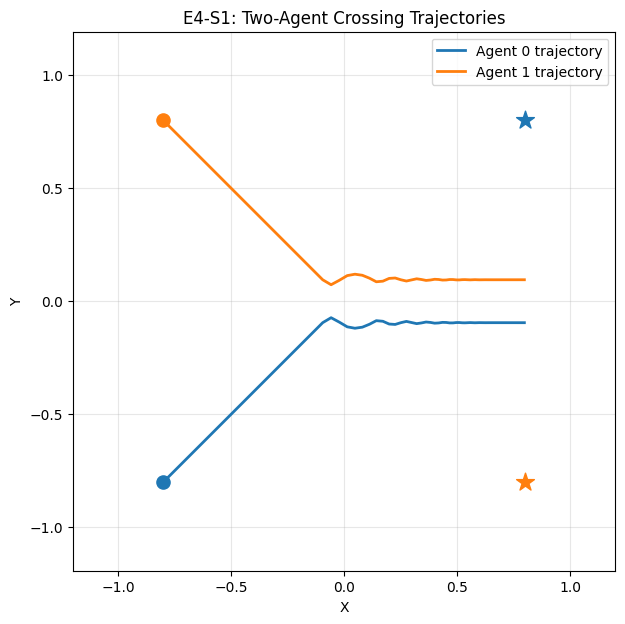

In [ ]:
#Step 7：绘制真实航路轨迹
import matplotlib.pyplot as plt

colors = ["tab:blue", "tab:orange"]

plt.figure(figsize=(7, 7))

for i, traj in enumerate(trajectories):
    plt.plot(
        traj[:, 0], traj[:, 1],
        color=colors[i],
        linewidth=2,
        label=f"Agent {i} trajectory"
    )
    plt.scatter(*starts[i], color=colors[i], marker="o", s=90)
    plt.scatter(*goals[i], color=colors[i], marker="*", s=180)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("E4-S1: Two-Agent Crossing Trajectories")
plt.axis("equal")
plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.grid(alpha=0.3)
plt.legend()
plt.show()


{
  "scenario": "E4_S1_crossing",
  "controller": "PD_baseline",
  "joint_success": false,
  "minimum_separation": 0.14590579271316528,
  "loss_of_separation": true,
  "collision_proxy": true,
  "planning_latency_mean_ms": 0.14535916001477744
}


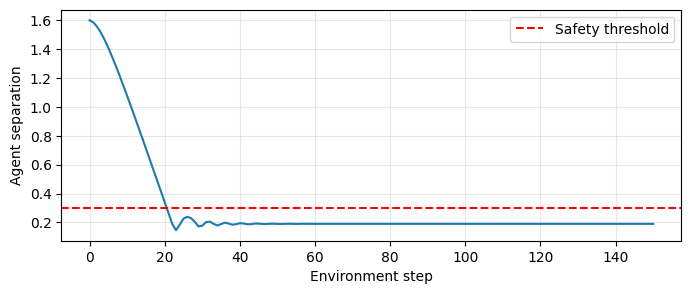

In [ ]:
#Step 8：计算安全指标
import json

min_separation = float(separations.min())
loss_of_separation = bool(np.any(separations < SAFE_DISTANCE))

# Agent 半径来自 VMAS 环境配置
collision_threshold = sum(
    float(a.shape.radius) for a in env.agents
)
collision_proxy = bool(np.any(separations < collision_threshold))

metrics = {
    "scenario": "E4_S1_crossing",
    "controller": "PD_baseline",
    "joint_success": bool(joint_success),
    "minimum_separation": min_separation,
    "loss_of_separation": loss_of_separation,
    "collision_proxy": collision_proxy,
    "planning_latency_mean_ms": float(
        np.mean(planning_times) * 1000
    ) if planning_times else 0.0
}

print(json.dumps(metrics, indent=2))

with open("E4_S1_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

plt.figure(figsize=(8, 3))
plt.plot(separations)
plt.axhline(SAFE_DISTANCE, linestyle="--",
            color="red", label="Safety threshold")
plt.xlabel("Environment step")
plt.ylabel("Agent separation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:
#Step 9：创建可复用的固定实验场景
import vmas
import torch
import numpy as np
import matplotlib.pyplot as plt
import time
import json

MAX_STEPS = 200
SAFE_DISTANCE = 0.30
GOAL_TOL = 0.12
KP = 1.5
KD = 1.0
SEED = 42

STARTS = np.array([
    [-0.8, -0.8],
    [-0.8,  0.8]
], dtype=np.float32)

GOALS = np.array([
    [0.8,  0.8],
    [0.8, -0.8]
], dtype=np.float32)

def create_scenario():
    device = "cuda" if torch.cuda.is_available() else "cpu"

    environment = vmas.make_env(
        scenario="navigation",
        num_envs=1,
        n_agents=2,
        device=device,
        continuous_actions=True,
        max_steps=MAX_STEPS,
        seed=SEED
    )

    environment.reset()

    with torch.no_grad():
        for i, agent in enumerate(environment.agents):
            pos = torch.tensor(
                STARTS[i], dtype=torch.float32, device=device
            )
            goal = torch.tensor(
                GOALS[i], dtype=torch.float32, device=device
            )

            agent.set_pos(pos, batch_index=0)
            agent.set_vel(torch.zeros_like(pos), batch_index=0)
            agent.goal.set_pos(goal, batch_index=0)

            # 同步 Navigation 的距离奖励基准
            if hasattr(agent, "pos_shaping"):
                agent.pos_shaping[0] = (
                    torch.linalg.vector_norm(pos - goal)
                    * environment.scenario.pos_shaping_factor
                )

    return environment

print("Scenario function created!")


Scenario function created!


In [ ]:
#Step 10：实现 Priority-Based PD 控制器

def run_experiment(mode="priority"):
    assert mode in ["independent", "priority"]

    env_exp = create_scenario()
    agents = env_exp.agents

    trajectories = [[], []]
    separations = []
    compute_times = []

    terminated_reason = "max_steps"
    phase = 0

    # 记录初始状态
    def record():
        positions = [
            a.state.pos[0].detach().cpu().numpy().copy()
            for a in agents
        ]
        for i in range(2):
            trajectories[i].append(positions[i])

        separations.append(
            float(np.linalg.norm(positions[0] - positions[1]))
        )

    def distances_to_goals():
        return [
            float(torch.linalg.vector_norm(
                a.state.pos[0] - a.goal.state.pos[0]
            ).item())
            for a in agents
        ]

    record()

    for step in range(MAX_STEPS):
        goal_dist = distances_to_goals()

        if all(d < GOAL_TOL for d in goal_dist):
            terminated_reason = "joint_success"
            break

        # Agent 0 到达目标后，允许 Agent 1 通行
        if mode == "priority" and goal_dist[0] < GOAL_TOL:
            phase = 1

        t0 = time.perf_counter()
        actions = []

        for i, agent in enumerate(agents):
            should_move = (
                mode == "independent"
                or (mode == "priority" and i == phase)
            )

            if should_move:
                pos = agent.state.pos
                vel = agent.state.vel
                goal = agent.goal.state.pos

                u = KP * (goal - pos) - KD * vel
            else:
                # 等待阶段使用速度阻尼，而不是直接冻结位置
                u = -KD * agent.state.vel

            u = torch.clamp(
                u, -float(agent.u_range), float(agent.u_range)
            )
            actions.append(u)

        compute_times.append(
            (time.perf_counter() - t0) * 1000
        )

        obs, rewards, dones, infos = env_exp.step(actions)
        record()

        if bool(torch.all(dones)):
            terminated_reason = "environment_done"
            break

    final_goal_dist = distances_to_goals()
    success = all(d < GOAL_TOL for d in final_goal_dist)

    trajectories = [np.array(t) for t in trajectories]
    separations = np.asarray(separations)

    collision_distance = sum(
        float(a.shape.radius) for a in agents
    )

    # 计算路径长度
    path_lengths = [
        float(np.linalg.norm(
            np.diff(t, axis=0), axis=1
        ).sum())
        for t in trajectories
    ]

    result = {
        "mode": mode,
        "steps": int(len(separations) - 1),
        "joint_success": bool(success),
        "termination_reason": terminated_reason,
        "min_separation": float(separations.min()),
        "loss_of_separation": bool(
            np.any(separations < SAFE_DISTANCE)
        ),
        "collision_proxy": bool(
            np.any(separations < collision_distance)
        ),
        "mean_control_ms": float(np.mean(compute_times))
            if compute_times else 0.0,
        "path_lengths": path_lengths,
        "final_goal_distances": final_goal_dist
    }

    return result, trajectories, separations

print("Controller ready!")


Controller ready!


In [ ]:
#Step 11：运行两组实验

result_a, traj_a, sep_a = run_experiment("independent")
result_b, traj_b, sep_b = run_experiment("priority")

print("=== Independent PD ===")
print(json.dumps(result_a, indent=2))

print("\n=== Priority-Based PD ===")
print(json.dumps(result_b, indent=2))


=== Independent PD ===
{
  "mode": "independent",
  "steps": 200,
  "joint_success": false,
  "termination_reason": "environment_done",
  "min_separation": 0.14590579271316528,
  "loss_of_separation": true,
  "collision_proxy": true,
  "mean_control_ms": 0.2948131249809194,
  "path_lengths": [
    1.9229402542114258,
    1.9229402542114258
  ],
  "final_goal_distances": [
    0.8950001001358032,
    0.8950001001358032
  ]
}

=== Priority-Based PD ===
{
  "mode": "priority",
  "steps": 150,
  "joint_success": true,
  "termination_reason": "joint_success",
  "min_separation": 1.027089238166809,
  "loss_of_separation": false,
  "collision_proxy": false,
  "mean_control_ms": 0.23279019999790762,
  "path_lengths": [
    2.158278465270996,
    2.1473569869995117
  ],
  "final_goal_distances": [
    0.10446307063102722,
    0.11538466811180115
  ]
}


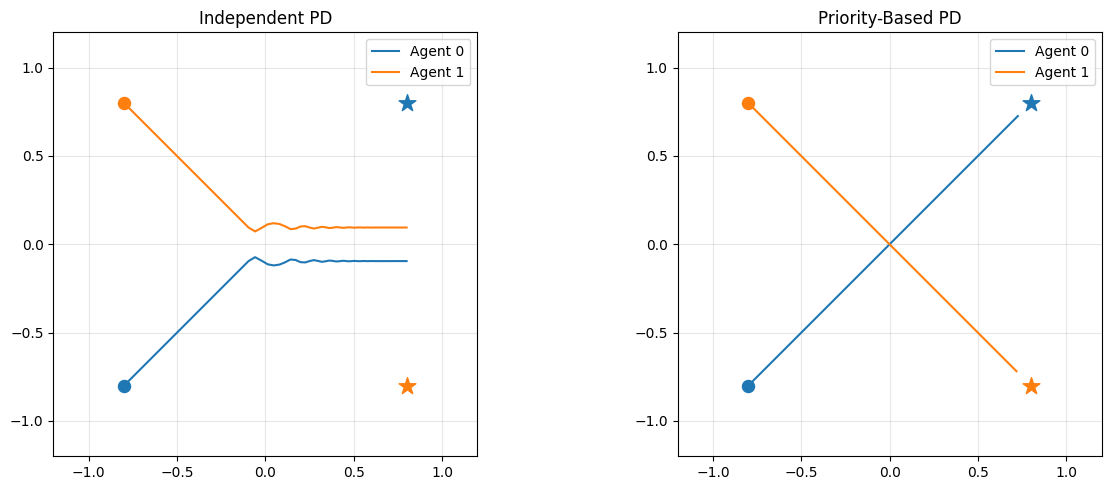

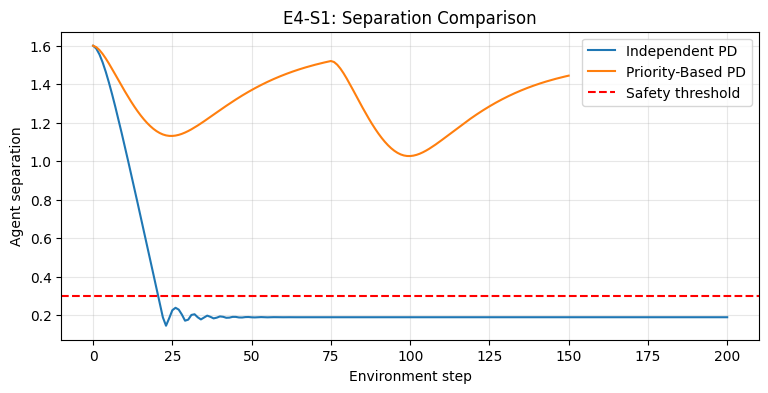

In [ ]:
#Step 12：绘制公平对照图

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

colors = ["tab:blue", "tab:orange"]

for ax, trajectories, name in [
    (axes[0], traj_a, "Independent PD"),
    (axes[1], traj_b, "Priority-Based PD")
]:
    for i, trajectory in enumerate(trajectories):
        ax.plot(
            trajectory[:, 0],
            trajectory[:, 1],
            color=colors[i],
            label=f"Agent {i}"
        )
        ax.scatter(*STARTS[i], color=colors[i], s=75)
        ax.scatter(
            *GOALS[i], color=colors[i],
            marker="*", s=160
        )

    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.set_title(name)
    ax.legend()

plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
plt.plot(sep_a, label="Independent PD")
plt.plot(sep_b, label="Priority-Based PD")

plt.axhline(
    SAFE_DISTANCE, color="red",
    linestyle="--", label="Safety threshold"
)

plt.xlabel("Environment step")
plt.ylabel("Agent separation")
plt.title("E4-S1: Separation Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:
#Step 13：保存实验结果

import os

os.makedirs("E4_results", exist_ok=True)

with open("E4_results/S1_PD_comparison.json", "w") as f:
    json.dump({
        "independent": result_a,
        "priority": result_b
    }, f, indent=2)

np.savez_compressed(
    "E4_results/S1_trajectories.npz",
    independent_agent0=traj_a[0],
    independent_agent1=traj_a[1],
    priority_agent0=traj_b[0],
    priority_agent1=traj_b[1],
    independent_separation=sep_a,
    priority_separation=sep_b
)

print("Results saved in E4_results/")


Results saved in E4_results/


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/MAWM_Research")
PD_DIR = ROOT / "E4" / "PD_baselines"

PD_DIR.mkdir(parents=True, exist_ok=True)

print("Saving to:", PD_DIR)

Saving to: /content/drive/MyDrive/MAWM_Research/E4/PD_baselines


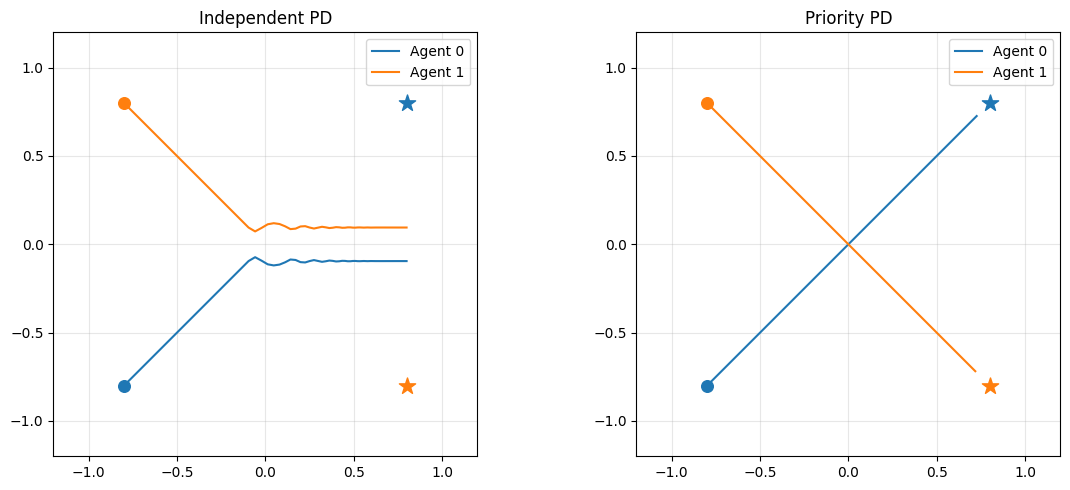

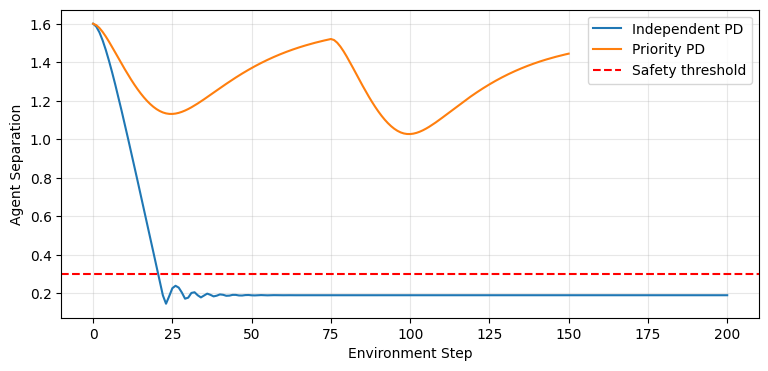

All PD results saved!
['S1_PD_comparison.json', 'S1_trajectories.npz', 'experiment_config.json', 'S1_trajectory_comparison.png', 'S1_separation_comparison.png']


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import json
import vmas
import torch
import importlib.metadata

# 1. 保存实验结果
with open(PD_DIR / "S1_PD_comparison.json", "w") as f:
    json.dump({
        "independent": result_a,
        "priority": result_b
    }, f, indent=2)

# 2. 保存原始运动轨迹
np.savez_compressed(
    PD_DIR / "S1_trajectories.npz",
    independent_agent0=traj_a[0],
    independent_agent1=traj_a[1],
    priority_agent0=traj_b[0],
    priority_agent1=traj_b[1],
    independent_separation=sep_a,
    priority_separation=sep_b
)

# 3. 保存实验参数
config = {
    "scenario": "E4_S1_crossing",
    "environment": "VMAS_navigation",
    "vmas_version": importlib.metadata.version("vmas"),
    "torch_version": torch.__version__,
    "seed": SEED,
    "max_steps": MAX_STEPS,
    "starts": STARTS.tolist(),
    "goals": GOALS.tolist(),
    "kp": KP,
    "kd": KD,
    "safe_distance": SAFE_DISTANCE,
    "goal_tolerance": GOAL_TOL,
    "controllers": ["independent", "priority"]
}

with open(PD_DIR / "experiment_config.json", "w") as f:
    json.dump(config, f, indent=2)

# 4. 保存轨迹对照图
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
colors = ["tab:blue", "tab:orange"]

for ax, trajectories, title in [
    (axes[0], traj_a, "Independent PD"),
    (axes[1], traj_b, "Priority PD")
]:
    for i, trajectory in enumerate(trajectories):
        ax.plot(
            trajectory[:, 0], trajectory[:, 1],
            color=colors[i], label=f"Agent {i}"
        )
        ax.scatter(*STARTS[i], color=colors[i], s=70)
        ax.scatter(*GOALS[i], color=colors[i],
                   marker="*", s=150)

    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()

fig.tight_layout()
fig.savefig(
    PD_DIR / "S1_trajectory_comparison.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

# 5. 保存安全间隔对照图
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(sep_a, label="Independent PD")
ax.plot(sep_b, label="Priority PD")
ax.axhline(SAFE_DISTANCE, color="red",
           linestyle="--", label="Safety threshold")
ax.set_xlabel("Environment Step")
ax.set_ylabel("Agent Separation")
ax.legend()
ax.grid(alpha=0.3)

fig.savefig(
    PD_DIR / "S1_separation_comparison.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

print("All PD results saved!")
print([p.name for p in PD_DIR.iterdir()])